### f-k examples: hammer impact and ambient flexural-gravity waves

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from datetime import datetime

from das_tools.utils import proj_path
from das_tools.readers import open_das, decimated
from das_tools.processing import hammer_utils as hu, pisces25
from das_tools.beamforming import cov_mat, das_beamforming
from das_tools.physics import dispersion_relations as dr

plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})

## Configuration

In [2]:
# ============================================================
# Paths
# ============================================================
DATA_DIR = proj_path.data_dir()
CH_GEO_FILE = DATA_DIR / "channel_geometry_20260908.npz"
HAMMER_FILES = sorted(proj_path.hammer_das_dir().glob("*.h5"))

# 2-D (f, k, theta) beamformer output from the earlier arctic-das pipeline;
# it does not store its k grid, see K_BF below. Without it, BF_HOUR is
# beamformed again from the decimated hourly file into BF2D_REBUILT_FILE.
BF2D_FILE = proj_path.output_dir(
    "bf2d", "decimator_2025-04-26_00.00.00_UTC_001114_BF2D_grid_result.npz")
BF2D_REBUILT_FILE = proj_path.output_dir("bf2d", "das_20250426_000000_5Hz_BF2D_rebuilt.npz")
LEG_GEO_FILE = DATA_DIR / "channel_geometry_20260908_L.npz"

FIG_DIR = proj_path.figures_dir("main_text", "5_fk_plots")
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_PDF = FIG_DIR / "fk_plots.pdf"

# ============================================================
# (a) hammer impact
# ============================================================
EVENT_NO = 2
# SH-wave window: seconds from the start of the file, metres along the cable
T1, T2 = 42.68, 42.92
D1, D2 = 1500.0, 1840.0
CH_CHANGE_DT = datetime(2025, 4, 24, 20, 24, 0)   # channels shift by -8 after this

K_HAMMER = np.linspace(0.01, 2.0, 201)   # [rad/m]
F_LIM_HAMMER = (10.0, 150.0)             # [Hz]

# ============================================================
# (b) ambient beamforming
# ============================================================
K_BF = np.arange(0.005, 0.300, 0.005)    # [rad/m], grid the BF2D file was built on
THETA_DEG = 294.0

# Only used to rebuild BF2D_FILE when it is missing; same grid as that file.
BF_HOUR = pd.Timestamp("2025-04-26 00:00")
BF_FMIN, BF_FMAX = 0.05, 1.0             # [Hz]
BF_WINDOW_S = 180.0                      # [s] snapshot length -> 1/180 Hz bins
BF_THETA_DEG = np.arange(0.0, 359.0, 1.0)

# ============================================================
# Ice / water properties for the model curves
# ============================================================
NU = 0.22
H_I = 0.98       # [m]
H_W = 10.0       # [m]
RHO_I = 910.0    # [kg/m^3]
RHO_W = 1025.0   # [kg/m^3]

E_HAMMER = 5.4e9                 # [Pa], P = 0
E_AMBIENT, P_AMBIENT = 0.6e9, 0.6e6   # [Pa]

## (a) Hammer-impact f-k

In [3]:
geo = np.load(CH_GEO_FILE)
ch_xy = geo["ch_xy"]

row = next(r for r in hu.get_all_tap_test_geoinfo_inv_all(DATA_DIR)
           if r["eventNo"] == EVENT_NO)
das = open_das(
    hu.find_das_file(HAMMER_FILES, row["timestamp"].strftime("%Y-%m-%d_%H.%M.00")),
    instrument="onyx",
    engine="h5py",
)
cable_dist = das["distance"].values
t0 = pd.Timestamp(das["time"].values[0])

i0 = np.argmin(np.abs(cable_dist - D1))
i1 = np.argmin(np.abs(cable_dist - D2))
ch_offset = 0 if row["timestamp"] < CH_CHANGE_DT else -8

# Source-receiver ranges for the channels in the window
src_xy = np.asarray(hu.ll_to_xy(row["lon"], row["lat"], geo["origin_lat"], geo["origin_lon"]))
r = np.linalg.norm(ch_xy[:, i0 + ch_offset:i1 + 1 + ch_offset] - src_xy[:, None], axis=0)

segment = das.isel(channel=slice(i0, i1 + 1)).sel(
    time=slice(t0 + pd.Timedelta(seconds=T1), t0 + pd.Timedelta(seconds=T2)))
XFK, freqs = hu.compute_FK(segment["strain"].values, das.attrs["fs"], K_HAMMER, r)

XFK_dB = 10 * np.log10(XFK)
XFK_dB -= XFK_dB.max(axis=1, keepdims=True)    # normalise each frequency

k_qs0 = dr.QS0(freqs, E_HAMMER, NU, RHO_I)
k_sh0 = dr.SH0(freqs, E_HAMMER, NU, RHO_I)
# the FG solver needs f > 1e-3 Hz, so the DC bin is evaluated at 1e-3
k_fg_hammer = dr.fg_disp_eq_ml_c_vec(np.maximum(freqs, 1e-3), E_HAMMER, NU,
                                     H_I, H_W, RHO_I, RHO_W, 0.0)

print(f"event {EVENT_NO} ({row['timestamp']}): {i1 - i0 + 1} channels, "
      f"{segment.sizes['time']} samples")

event 2 (2025-04-24 00:27:36.894900): 108 channels, 121 samples


## (b) Ambient beamforming at one azimuth

In [4]:
def build_bf2d(hour, out_path):
    """Beamform one decimated hour on (f, K_BF, BF_THETA_DEG) and save it in the BF2D layout.

    A stand-in for the arctic-das BF2D file, not a bit-for-bit copy: consecutive
    BF_WINDOW_S snapshots are band-passed and transformed (cov_mat.snapshot_covariance),
    then averaged into R(f) either as they are ("raw") or each scaled to unit trace,
    i.e. unit norm across channels ("unitnorm"). B = a^H R a with unit-modulus
    plane-wave steering vectors a, as in the old file.
    """
    loaded = decimated.load_block(decimated.index_hourly_files(proj_path.hourly_das_dir()),
                                  hour, hour + pd.Timedelta(hours=1))
    if loaded is None:
        raise FileNotFoundError(f"No decimated file for {hour} in {proj_path.hourly_das_dir()}")
    block, channel, fs = loaded
    ch_xy, _ = pisces25.load_leg_geometry(LEG_GEO_FILE, channel)

    band = das_beamforming.make_band(BF_FMIN, BF_FMAX, BF_WINDOW_S, cov_duration_h=1.0)
    n_win = round(BF_WINDOW_S * fs)
    R_raw = R_unit = 0.0
    n_valid = 0
    for i in range(block.shape[0] // n_win):
        result = cov_mat.snapshot_covariance(block[i * n_win:(i + 1) * n_win], fs, band)
        if result is None:      # window with a gap
            continue
        Rk, freq = result
        R_raw = R_raw + Rk
        R_unit = R_unit + Rk / np.real(np.trace(Rk, axis1=1, axis2=2))[:, None, None]
        n_valid += 1
    if n_valid == 0:
        raise ValueError(f"No gap-free {BF_WINDOW_S:g} s window in {hour}")

    theta = np.deg2rad(BF_THETA_DEG)
    A = das_beamforming.steering_matrix(K_BF, theta, ch_xy).conj() * np.sqrt(ch_xy.shape[1])
    B = {mode: np.stack([das_beamforming.quadratic_form(Rf / n_valid, A)[0] for Rf in R])
                 .reshape(freq.size, K_BF.size, theta.size)
         for mode, R in (("unitnorm", R_unit), ("raw", R_raw))}

    out_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(out_path, freq=freq, k=K_BF, theta_deg=BF_THETA_DEG, theta_rad=theta,
             fmin=BF_FMIN, fmax=BF_FMAX, n_snapshots=n_valid,
             is_unitnorm_modes=np.array(["unitnorm", "raw"]),
             B_unitnorm=B["unitnorm"], B_raw=B["raw"])
    print(f"{n_valid} snapshots of {hour} beamformed -> {out_path}")


if BF2D_FILE.is_file():
    bf_path = BF2D_FILE
else:
    bf_path = BF2D_REBUILT_FILE
    if not bf_path.is_file():
        print(f"No {BF2D_FILE.name}; rebuilding it from the decimated data.")
        build_bf2d(BF_HOUR, bf_path)
print(f"beamformer output: {bf_path.name}")

beamformer output: das_20250426_000000_5Hz_BF2D_rebuilt.npz


In [5]:
bf = np.load(bf_path)
freq_bf = bf["freq"]
i_theta = np.argmin(np.abs(bf["theta_deg"] - THETA_DEG))
B = np.abs(bf["B_unitnorm"][:, :, i_theta])
assert B.shape[1] == K_BF.size, f"K_BF does not match {bf_path.name}"

B_dB = 20 * np.log10(B)
B_dB -= B_dB.max()

k_fg_ambient = dr.fg_disp_eq_ml_c_vec(freq_bf, E_AMBIENT, NU, H_I, H_W,
                                      RHO_I, RHO_W, P_AMBIENT)

## The figure

wrote /Users/junsuj/Desktop/git/das-landfast-ice-inversion2025/figures/main_text/5_fk_plots/fk_plots.pdf


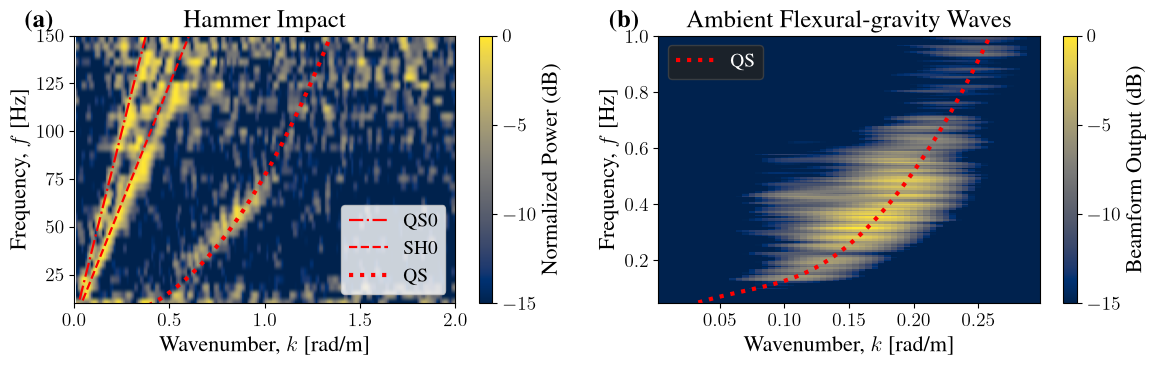

In [ ]:
fig, (ax_h, ax_fg) = plt.subplots(1, 2, figsize=(12.0, 4.0))

# ---------------- (a) hammer impact ----------------
im = ax_h.imshow(
    XFK_dB,
    aspect="auto",
    origin="lower",
    cmap="cividis",
    vmin=-15,
    vmax=0,
    extent=[K_HAMMER[0], K_HAMMER[-1], freqs.min(), freqs.max()],
)
cb = fig.colorbar(im, ax=ax_h)
cb.set_label("Normalized Power (dB)")
cb.set_ticks([0, -5, -10, -15])

ax_h.plot(k_qs0, freqs, color="r", linestyle="-.", linewidth=1.6, label="QS0")
ax_h.plot(k_sh0, freqs, color="r", linestyle="--", linewidth=1.6, label="SH0")
ax_h.plot(k_fg_hammer, freqs, color="r", linestyle=":", linewidth=3, label="QS")

ax_h.set_xlim(0, 2.0)
ax_h.set_ylim(F_LIM_HAMMER)
ax_h.set_title("Hammer Impact")
ax_h.set_xlabel(r"Wavenumber, $k$ [rad/m]")
ax_h.set_ylabel(r"Frequency, $f$ [Hz]")
ax_h.legend(loc="lower right")

# ---------------- (b) ambient flexural-gravity waves ----------------
im = ax_fg.pcolormesh(K_BF, freq_bf, B_dB, cmap="cividis", vmin=-15, vmax=0)
cb = fig.colorbar(im, ax=ax_fg)
cb.set_label("Beamform Output (dB)")
cb.set_ticks([0, -5, -10, -15])

ax_fg.plot(k_fg_ambient, freq_bf, color="r", linestyle=":", linewidth=3.0, label="QS")

ax_fg.set_title("Ambient Flexural-gravity Waves")
ax_fg.set_xlabel(r"Wavenumber, $k$ [rad/m]")
ax_fg.set_ylabel(r"Frequency, $f$ [Hz]")
ax_fg.legend(loc="upper left", facecolor="#222222", edgecolor="#444444",
             labelcolor="white")

# Panel labels on the title line, pulled left of the axes to clear the titles
for label, ax in zip(["(a)", "(b)"], [ax_h, ax_fg]):
    ax.set_title(rf"\textbf{{{label}}}", loc="right", x=-0.13)

fig.tight_layout()
fig.savefig(OUT_PDF)
print(f"wrote {OUT_PDF}")

plt.show()